AI usage: Gemini helped with parallelizing download. I checked all of the modified code to the best of my ability.


In [3]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.dummy import DummyClassifier

**Download Dataset**

In [ ]:
import os
import requests
import requests
from tqdm.notebook import tqdm

dataset_url = "https://api.biodiversitydata.nl/v2/specimen/dwca/getDataSet/wildlife-sounds-birds"
write_path = "wildlife-sounds-birds-20260928.dwca.zip"

try:
    with requests.get(dataset_url, timeout=10, stream=True) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0))

        with open(write_path, "wb") as handler:
            with tqdm(
                total=total or None,
                unit="B",
                unit_scale=True,
                desc="Downloading",
            ) as bar:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        handler.write(chunk)
                        bar.update(len(chunk))

except requests.RequestException as e:
    print(f"Failed to download {dataset_url}: {e}")

Downloading: 0.00B [00:00, ?B/s]

**Extract Data**

In [ ]:
zip_path = "/data" + write_path

In [14]:
# import packages first
!pip install python-dwca-reader

from dwca.read import DwCAReader
import pandas as pd

Create DataFrame (with merged core and extension):

In [16]:
pd.set_option('display.max_colwidth', None) # avoid truncating the urls

with DwCAReader(zip_path) as dwca:
  # get the 'core'
  df_core = dwca.pd_read(dwca.core_file_location)

  # get the extensions of the core
  ext_file = dwca.extension_files[0] # get name of ext file
  df_ext = dwca.pd_read(str(ext_file))

  # strip out important info and change 'coreid' to 'id'
  datatype = 'Sound'
  df_ext_urls = df_ext[df_ext['type'] == datatype].drop_duplicates(subset=['coreid']) # drop non-audio files and any extra entries
  df_ext_urls = df_ext_urls[['coreid', 'accessURI', 'type', 'rights']]
  df_ext_urls.rename(columns={'coreid':'id'}, inplace = True)

  # merge the core and its extensions on 'id'
  df_merged = pd.merge(df_core[['id', 'scientificName', 'vernacularName']], df_ext_urls, on='id')

df_merged

c:\Users\Fener\AppData\Local\Programs\Python\Python312\Lib\site-packages\dwca\read.py:242: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df_or_textreader = read_csv(


,id,scientificName,vernacularName,accessURI,type,rights
0,9@XC,Synallaxis azarae media,Azara's Spinetail,https://xeno-canto.org/sounds/uploaded/OH38YHKJBS/azaras_spinetail.mp3,Sound,CC BY-NC-SA 3.0
1,99@XC,Turdus hauxwelli,Hauxwell's Thrush,https://xeno-canto.org/sounds/uploaded/OH38YHKJBS/BlackbilledThrush-los2-54.mp3,Sound,CC BY-NC-SA 3.0
2,9999@XC,Myrmothera campanisona signata,Thrush-like Antpitta,https://xeno-canto.org/sounds/uploaded/AZXTZTQJRO/Myrmothera_campanisona_EC-Sacha_19980304_S1_ATC.mp3,Sound,CC BY-NC-SA 3.0
3,999999@XC,Turdus mandarinus,Chinese Blackbird,https://xeno-canto.org/sounds/uploaded/YNOAMCSSHX/XC999999-Chinese-Blackbird-%E4%B9%8C%E9%B8%AB-song-%E6%B5%B7%E6%B9%BE%E5%A3%B0%E7%BA%B9%E7%9B%91%E6%8E%A7-B67B_20250119_065012.mp3,Sound,CC BY-NC-SA 4.0
4,999998@XC,Treron curvirostra,Thick-billed Green Pigeon,https://xeno-canto.org/sounds/uploaded/KQMHASAYBL/XC999998-%E5%8E%9A%E5%98%B4%E7%BB%BF%E9%B8%A0song-%E5%84%8B%E5%B7%9E%E6%9D%BE%E6%B6%9B%E6%B0%B4%E5%BA%932.mp3,Sound,CC BY-NC-SA 4.0
...,...,...,...,...,...,...
936759,1000004@XC,Dicaeum cruentatum,Scarlet-backed Flowerpecker,https://xeno-canto.org/sounds/uploaded/KQMHASAYBL/XC1000004-%E6%9C%B1%E8%83%8C%E5%95%84%E8%8A%B1%E9%B8%9Fcall%2C-alarm-call-%E5%84%8B%E5%B7%9E%E6%9D%BE%E6%B6%9B%E6%B0%B4%E5%BA%93.mp3,Sound,CC BY-NC-SA 4.0
936760,1000003@XC,Erpornis zantholeuca,White-bellied Erpornis,https://xeno-canto.org/sounds/uploaded/KQMHASAYBL/XC1000003-%E7%99%BD%E8%85%B9%E5%87%A4%E9%B9%9Bcall%2C-alarm-call-%E5%84%8B%E5%B7%9E%E6%9D%BE%E6%B6%9B%E6%B0%B4%E5%BA%93.mp3,Sound,CC BY-NC-SA 4.0
936761,1000002@XC,Turdus mandarinus,Chinese Blackbird,https://xeno-canto.org/sounds/uploaded/YNOAMCSSHX/XC1000002-Chinese-Blackbird-%E4%B9%8C%E9%B8%AB-song%E6%B5%B7%E6%B9%BE%E5%A3%B0%E7%BA%B9%E7%9B%91%E6%8E%A7-B67B_20250208_055002---A.mp3,Sound,CC BY-NC-SA 4.0
936762,1000001@XC,Psilopogon faber,Chinese Barbet,https://xeno-canto.org/sounds/uploaded/KQMHASAYBL/XC1000001-%E9%BB%91%E7%9C%89%E6%8B%9F%E5%95%84%E6%9C%A8%E9%B8%9Fcall-%E5%84%8B%E5%B7%9E%E6%9D%BE%E6%B6%9B%E6%B0%B4%E5%BA%93.mp3,Sound,CC BY-NC-SA 4.0


Code for checking individual counts of bird samples (to ensure there are at least 200):

(not necessary to run)

In [17]:
count = df_merged['vernacularName'].value_counts().get("Thrush-like Antpitta", 0)
count

np.int64(192)

In [ ]:
# df_merged['vernacularName'].value_counts()[40:45]

: 

New `DataFrame` with 5 birds and 200 samples for each:

In [18]:
# selected_birds = ['Common Blackbird', 'Common Chiffchaff', 'Great Tit', 'Common Chaffinch', 'European Robin']
selected_birds = ["Azara's Spinetail", 'Mourning Dove', 'Yellowhammer', 'Eurasian Nuthatch', 'European Robin']

df_sampled = df_merged[df_merged['vernacularName'].isin(selected_birds)].groupby('vernacularName',group_keys=False).apply(lambda x: x.sample(200))
df_sampled

C:\Users\Fener\AppData\Local\Temp\ipykernel_15236\2978368863.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sampled = df_merged[df_merged['vernacularName'].isin(selected_birds)].groupby('vernacularName',group_keys=False).apply(lambda x: x.sample(200))


,id,scientificName,vernacularName,accessURI,type,rights
179907,779780@XC,Synallaxis azarae,Azara's Spinetail,https://xeno-canto.org/sounds/uploaded/JPBSNBUUEF/XC779780-Azara-s-Spinetail%2C-El-Chorro%2C-230210-027.wav,Sound,CC BY-NC-SA 4.0
419095,529670@XC,Synallaxis azarae,Azara's Spinetail,https://xeno-canto.org/sounds/uploaded/XMFDPACYJN/XC529670-x_IAvH-CSA-7708.mp3,Sound,CC BY-NC-SA 4.0
668605,260636@XC,Synallaxis azarae media,Azara's Spinetail,https://xeno-canto.org/sounds/uploaded/OWZTPLFLJS/XC260636-59.009.05.Azara%27s_Spinetail.mp3,Sound,CC BY-NC-SA 4.0
620808,311809@XC,Synallaxis azarae,Azara's Spinetail,https://xeno-canto.org/sounds/uploaded/NQMGMOJOHV/XC311809-Sinallaxis%20azarae%20%28Jardin%29%202.MP3,Sound,CC BY-NC-SA 4.0
779248,129015@XC,Synallaxis azarae,Azara's Spinetail,https://xeno-canto.org/sounds/uploaded/CSUHASNRSU/XC129015-Synallaxis%20azarae%20song%20OHM065A1050%2004ene2010.mp3,Sound,CC BY-NC-SA 3.0
...,...,...,...,...,...,...
219353,737521@XC,Emberiza citrinella,Yellowhammer,https://xeno-canto.org/sounds/uploaded/HNYFHZLJOD/XC737521-220714-YH%20clip.mp3,Sound,CC BY-NC-SA 4.0
415169,533755@XC,Emberiza citrinella citrinella,Yellowhammer,https://xeno-canto.org/sounds/uploaded/BTOFEKXFGW/XC533755-MIXPRE-701.mp3,Sound,CC BY-NC-ND 4.0
773784,136046@XC,Emberiza citrinella,Yellowhammer,https://xeno-canto.org/sounds/uploaded/RFGQDPLDEC/XC136046-Gulspurv%20XC%20Staur%2001.06.2013%20kl.%2020.30%20.mp3,Sound,CC BY-NC-SA 3.0
687668,240551@XC,Emberiza citrinella,Yellowhammer,https://xeno-canto.org/sounds/uploaded/BTOFEKXFGW/XC240551-T08.mp3,Sound,CC BY-NC-ND 4.0


**Download the Data**

In [21]:
# adapted for parallelization with Gemini

import os
import requests
from tqdm.notebook import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

top_dir = 'bird_recordings/'

# create directory structure
for name in selected_birds:
  if not os.path.exists(top_dir+name):
    os.makedirs(top_dir+name)

# Convert sampled dataframe to list of dicts/tuples for easy mapping
download_tasks = []
for counter, bird in enumerate(df_sampled.itertuples(index=False)):
  sub_dir = bird.vernacularName + '/'
  filename = f"{counter}.mp3"
  filepath = os.path.join(top_dir, sub_dir, filename)
  download_tasks.append((bird.accessURI, filepath))

def download_image(task):
  url, filepath = task
  try:
    img_data = requests.get(url, timeout=10).content
    with open(filepath, 'wb') as handler:
      handler.write(img_data)
    return True
  except Exception as e:
    # Return the error or False so we can track issues if necessary
    return (url, str(e))

# download the files in parallel using ThreadPoolExecutor
num_workers = 16  # Adjust based on system resources and server limitations
results = []

with ThreadPoolExecutor(max_workers=num_workers) as executor:
  # Submit all download tasks
  futures = {executor.submit(download_image, task): task for task in download_tasks}

  # Process futures as they complete with a progress bar
  for future in tqdm(as_completed(futures), total=len(futures), desc="Downloading bird spectrograms in parallel"):
    res = future.result()
    if res != True:
      print(f"Failed to download {res[0]}: {res[1]}")

In [22]:
#!pip install librosa
#Making changes from previous download base
#I did it together with chatgpt because I couldn't get results without large amounts of download errors
import os
import time
import random
import requests
import librosa

from tqdm.notebook import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed


#check if an audio file exists and if can be read
def check_audio(filepath):
    try:
        #Check if the file exists
        if not os.path.isfile(filepath):
            return False

        #Check if the file is empty
        if os.path.getsize(filepath) == 0:
            return False

        #Load the complete audio to check for errors
        y, sr = librosa.load(filepath, sr=None)

        #Make sure the audio contains samples
        return len(y) > 0 and sr > 0

    except Exception:
        return False


#Function for Download audio file
def download_audio(task):
    url, filepath = task
    max_attempts = 3
    temp_path = filepath + ".part"

    #Skip files that were already downloaded and validated
    if check_audio(filepath):
        return ("skipped", filepath)

    #Try downloading the file up to three times to maximize downloads
    for attempt in range(max_attempts):
        try:
            #Request the audio file from the server
            response = requests.get(
                url,
                timeout=(5, 20)
            )

            #Check for HTTP errors such as 503
            response.raise_for_status()

            #Check if the downloaded file is empty
            if not response.content:
                return ("failed", filepath, "Empty download")

            #save the file temporarily before replacing anything
            with open(temp_path, "wb") as file:
                file.write(response.content)

            #heck if Librosa can read the downloaded file
            if not check_audio(temp_path):
                return ("failed", filepath, "Invalid audio file")

            #Keep the file only after it passes validation
            os.replace(temp_path, filepath)

            return ("downloaded", filepath)

        except requests.exceptions.RequestException as e:

            #Get the HTTP error code if available
            status = (
                e.response.status_code
                if isinstance(e, requests.exceptions.HTTPError)
                and e.response is not None
                else None
            )

            #Retry temporary server or connection errors
            retryable = (
                status in [429, 500, 502, 503, 504]
                or isinstance(
                    e,
                    (
                        requests.exceptions.Timeout,
                        requests.exceptions.ConnectionError
                    )
                )
            )

            #Stop if the error cannot be retried
            if not retryable or attempt == max_attempts - 1:
                return ("failed", filepath, str(e))

            #wait longer before trying again to unsure proper download
            wait_time = (2 ** attempt) + random.uniform(0, 1)
            time.sleep(wait_time)

        except Exception as e:
            return ("failed", filepath, str(e))

        finally:
            #remove any temporary file left after the attempt
            if os.path.exists(temp_path):
                os.remove(temp_path)

    return ("failed", filepath, "Download failed")


#download audio files in parallel, two workers in parallel
num_workers = 2
results = []

with ThreadPoolExecutor(max_workers=num_workers) as executor:

    #Start all download tasks
    futures = {
        executor.submit(download_audio, task): task
        for task in download_tasks
    }

    #process each task as it finishes
    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Downloading bird audio files"
    ):
        result = future.result()
        results.append(result)

        #Show only failed downloads
        if result[0] == "failed":
            print(f"Failed: {result[1]} - {result[2]}")


#Counter for the download results
downloaded = sum(r[0] == "downloaded" for r in results)
skipped = sum(r[0] == "skipped" for r in results)
failed = sum(r[0] == "failed" for r in results)

#show the final summary of the downloads
print("\nDownload Summary")
print(f"New downloads: {downloaded}")
print(f"Existing files reused: {skipped}")
print(f"Failed downloads: {failed}")
print(f"Total files checked: {len(results)}")


Failed: bird_recordings/European Robin/563.mp3 - Invalid audio file
Failed: bird_recordings/Yellowhammer/829.mp3 - Invalid audio file
Failed: bird_recordings/Yellowhammer/985.mp3 - 404 Client Error: Not Found for url: https://xeno-canto.org/sounds/uploaded/BTOFEKXFGW/MixPre-013.WAV

Download Summary
New downloads: 96
Existing files reused: 901
Failed downloads: 3
Total files checked: 1000


3028 bytes is an empty mp3:

In [ ]:
!ls -l /content/bird_recordings/Eurasian\ Nuthatch


'ls' is not recognized as an internal or external command,
operable program or batch file.


: 

Checking the audio server

In [23]:
import requests

#Select one audio URL from our dataset
test_url = df_sampled.iloc[0]["accessURI"]

try:
    #send only one request to check the server to see if the problems were the urls
    response = requests.get(
        test_url,
        timeout=30,
        stream=True
    )

    print("HTTP status:", response.status_code)
    print("Content type:", response.headers.get("Content-Type"))
    print("Retry after:", response.headers.get("Retry-After"))

    response.close()

except requests.exceptions.RequestException as e:
    print("Connection error", e)

    #HTTP 200 OK successful response status code indicates that a request has succeeded
    #all good no need further changes within the url

HTTP status: 200
Content type: application/octet-stream
Retry after: None


Checking the download tasks 

In [24]:
#Check how many recordings we want to download
print(f"Total download tasks: {len(download_tasks)}")

#get the URLs from our download tasks
urls = [url for url, filepath in download_tasks]

#Check if any URLs are repeated to avoid conflict
print(f"Unique URLs: {len(set(urls))}")
print(f"Repeated URLs: {len(urls) - len(set(urls))}")


# 200 recordings per bird species, 5 species, 1000 recordings in total (downloads)

Total download tasks: 1000
Unique URLs: 1000
Repeated URLs: 0


Manifest


In [25]:
import pandas as pd
#Will impliment a manifest help to se our downloads
# Create a table that connects each audio URL to its saved file path
#helping us identify the original recording if a download fails
#also preventing us from mixing recordings when we rerun the notebook
download_manifest = pd.DataFrame(
    download_tasks,
    columns=["url", "filepath"]
)

#Save the table so we can recover failed downloads later
manifest_path = os.path.join(top_dir, "bird_download_manifest.csv")

#Check if we already have a manifest from a previous download
if os.path.exists(manifest_path):
    old_manifest = pd.read_csv(manifest_path)

    #Stop if the selected recordings or file paths have changed unwanted changes
    #preveents us from reusing files that belong to different URLs
    if not old_manifest.equals(download_manifest):
        raise ValueError(
            "the download selection has changed "
            "use a new folder to avoid mixing recordings"
        )
else:
    download_manifest.to_csv(manifest_path, index=False)

print("download manifest ready")

download manifest ready


Visualize the names of the birds (5)

In [28]:
# !pip install librosa
import librosa
import librosa.display
import IPython.display as ipd
import os
for file in os.listdir('bird_recordings/'):
  if file not in ['.ipynb_checkpoints', 'bird_download_manifest.csv']:
    print(file)

Azara's Spinetail
Eurasian Nuthatch
European Robin
Mourning Dove
Yellowhammer


Preparing the audio dataset

In [29]:
import os
import pandas as pd

#Create a list of recordings that were downloaded successfully
audio_data = []

for url, filepath in download_tasks:

    #O0nly include files that exist
    if check_audio(filepath):

        #Get the bird species from the folder name
        species = os.path.basename(os.path.dirname(filepath))

        audio_data.append({
            "filepath": filepath,
            "species": species
        })

#convert the list into our DataFrame
audio_df = pd.DataFrame(audio_data)

#Check how many recordings we have for each species
print("total valid recordings:", len(audio_df))
print("\nrrecordings per species:")
print(audio_df["species"].value_counts())

total valid recordings: 997

rrecordings per species:
species
Azara's Spinetail    200
Eurasian Nuthatch    200
Mourning Dove        200
European Robin       199
Yellowhammer         198
Name: count, dtype: int64


Splitting dataset into train, validation, and test sets

In [30]:
from sklearn.model_selection import train_test_split

#Split the dataset into 70% training and 30% temporary data(could change)
train_df, temp_df = train_test_split(
    audio_df,
    test_size=0.30,
    random_state=42,
    stratify=audio_df["species"]
)

#Split the remaining 30% equally into validation and testing data
# 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["species"]
)

#check the number of recordings in each dataset
print(f"training recordings: {len(train_df)}")
print(f"validation recordings: {len(val_df)}")
print(f"testing recordings: {len(test_df)}")

#check the distribution of bird species within each category
print("\ntraining:")
print(train_df["species"].value_counts())

print("\nvalidation:")
print(val_df["species"].value_counts())

print("\ntesting:")
print(test_df["species"].value_counts())

training recordings: 697
validation recordings: 150
testing recordings: 150

training:
species
Mourning Dove        140
Eurasian Nuthatch    140
Azara's Spinetail    140
European Robin       139
Yellowhammer         138
Name: count, dtype: int64

validation:
species
Mourning Dove        30
European Robin       30
Azara's Spinetail    30
Eurasian Nuthatch    30
Yellowhammer         30
Name: count, dtype: int64

testing:
species
Mourning Dove        30
Yellowhammer         30
Eurasian Nuthatch    30
European Robin       30
Azara's Spinetail    30
Name: count, dtype: int64


Function for extracting MFCC features and returns them

Current feature count: 15

In [248]:
import numpy as np
import pandas as pd
import librosa

from tqdm.notebook import tqdm


# Extract audio features from one recording
def extract_mfcc(filepath):

    # Load audio
    y, sr = librosa.load(
        filepath,
        sr=22050,
        mono=True
    )

    # Skip recordings that are too short
    if len(y) < 2048:
        raise ValueError("Audio recording is too short")

    # ----------------------------------
    # 1. MFCC FEATURES
    # ----------------------------------

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=20
    )

    # Calculate first-order delta
    mfcc_delta = librosa.feature.delta(
        mfcc,
        order=1
    )

    # Calculate second-order delta
    mfcc_delta2 = librosa.feature.delta(
        mfcc,
        order=2
    )

    # MFCC statistics
    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)


    # Delta-delta statistics
    delta2_mean = np.mean(mfcc_delta2, axis=1)
    delta2_std = np.std(mfcc_delta2, axis=1)



    # ----------------------------------
    # 7. SPECTRAL CONTRAST
    # ----------------------------------

    spectral_contrast = librosa.feature.spectral_contrast(
        y=y,
        sr=sr
    )

    contrast_mean = np.mean(spectral_contrast, axis=1)
    contrast_std = np.std(spectral_contrast, axis=1)


    # ----------------------------------
    # 9. COMBINE ALL FEATURES
    # ----------------------------------

    features = np.concatenate([

        # MFCC: 40
        mfcc_mean,
        mfcc_std,

        # MFCC Delta-Delta: 40
        delta2_mean,
        delta2_std,

       
        # Spectral Contrast: 14
        contrast_mean,
        contrast_std,

    ])

    return features

In [249]:
import pandas as pd
from tqdm.notebook import tqdm

#Extract MFCC features from a dataset
def process_dataset(dataset):

    features_list = []
    labels = []
    filepaths = []
    failed_files = []

    for row in tqdm(
        dataset.itertuples(index=False),
        total=len(dataset),
        desc="extracting MFCC"
    ):
        try:
            #Extract the 40 MFCC features
            features = extract_mfcc(row.filepath)

            #Check that all features contain valid numbers
            if not np.all(np.isfinite(features)):
                raise ValueError("Invalid MFCC values")

            features_list.append(features)
            labels.append(row.species)
            filepaths.append(row.filepath)

        except Exception as e:
            failed_files.append((row.filepath, str(e)))

    #Create the DataFrame with the extracted features
    feature_columns = (
        # 20 + 20
        [f"mfcc_mean_{i}" for i in range(1, 21)] +
        [f"mfcc_std_{i}" for i in range(1, 21)] +

        # MFCC Delta-Delta
        [f"delta2_mean_{i}" for i in range(1, 21)] +
        [f"delta2_std_{i}" for i in range(1, 21)] +
        # Spectral Contrast
        [f"contrast_mean_{i}" for i in range(1, 8)] +
        [f"contrast_std_{i}" for i in range(1, 8)] 
    )

    mfcc_df = pd.DataFrame(
        features_list,
        columns=feature_columns
    )

    #Add the species label and original filepath
    mfcc_df["species"] = labels
    mfcc_df["filepath"] = filepaths

    return mfcc_df, failed_files


#Extract features separately for each dataset
train_mfcc, train_failed = process_dataset(train_df)
val_mfcc, val_failed = process_dataset(val_df)
test_mfcc, test_failed = process_dataset(test_df)

print("\nMFCC Extraction Summary")
print(f"training: {len(train_mfcc)} recordings, {len(train_failed)} failed")
print(f"validation: {len(val_mfcc)} recordings, {len(val_failed)} failed")
print(f"testing: {len(test_mfcc)} recordings, {len(test_failed)} failed")

#Saave stracted features
#each dataset with its MFCC features and species labels
train_mfcc.to_csv("bird_train_mfcc.csv", index=False)
val_mfcc.to_csv("bird_validation_mfcc.csv", index=False)
test_mfcc.to_csv("bird_test_mfcc.csv", index=False)

print("MFCC datasets saved")

#View the training features
display(train_mfcc.head())

extracting MFCC:   0%|          | 0/697 [00:00<?, ?it/s]

extracting MFCC:   0%|          | 0/150 [00:00<?, ?it/s]

extracting MFCC:   0%|          | 0/150 [00:00<?, ?it/s]


MFCC Extraction Summary
training: 697 recordings, 0 failed
validation: 150 recordings, 0 failed
testing: 150 recordings, 0 failed
MFCC datasets saved


,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7,mfcc_mean_8,mfcc_mean_9,mfcc_mean_10,...,contrast_mean_7,contrast_std_1,contrast_std_2,contrast_std_3,contrast_std_4,contrast_std_5,contrast_std_6,contrast_std_7,species,filepath
0,-530.681824,18.177332,-1.034940,12.913311,-19.473755,-11.089752,-21.830090,-19.954077,-22.645691,-12.157240,...,46.770164,4.860150,3.299457,6.368486,3.432484,2.876166,3.052258,3.342828,Mourning Dove,bird_recordings/Mourning Dove/684.mp3
1,-560.392456,-75.162483,-28.845303,-15.122305,-18.410597,-11.751891,-14.854800,0.762929,-16.331539,-3.211748,...,47.123959,4.995666,3.074994,2.959758,1.991092,3.648184,1.777093,2.523145,Eurasian Nuthatch,bird_recordings/Eurasian Nuthatch/231.mp3
2,-242.164108,33.389030,12.697487,24.751238,-5.219515,7.656591,3.788172,1.388478,-5.028670,1.923864,...,46.008087,3.147418,2.978865,3.038305,1.962142,3.425771,5.361719,4.735212,Yellowhammer,bird_recordings/Yellowhammer/876.mp3
3,-485.188324,76.762222,5.839108,30.917255,13.963512,22.293064,11.022813,2.089542,5.182840,13.869292,...,46.363586,4.389463,2.919729,2.960266,4.337540,5.646813,3.621027,2.858112,Azara's Spinetail,bird_recordings/Azara's Spinetail/155.mp3
4,-447.413483,-31.886654,-115.984077,12.027045,-30.828588,-2.518164,-4.621445,4.837274,-14.227217,13.184637,...,57.110626,4.592860,4.293781,3.010570,2.157159,3.914135,6.900715,5.026929,Eurasian Nuthatch,bird_recordings/Eurasian Nuthatch/320.mp3


making sure all columns are visible

In [251]:
print(f"Total columns: {train_mfcc.shape[1]}")
print(f"Numeric feature columns: {train_mfcc.select_dtypes(include="number").shape[1]}")
print("All column names:")
print(train_mfcc.columns.tolist())

Total columns: 96
Numeric feature columns: 94
All column names:
['mfcc_mean_1', 'mfcc_mean_2', 'mfcc_mean_3', 'mfcc_mean_4', 'mfcc_mean_5', 'mfcc_mean_6', 'mfcc_mean_7', 'mfcc_mean_8', 'mfcc_mean_9', 'mfcc_mean_10', 'mfcc_mean_11', 'mfcc_mean_12', 'mfcc_mean_13', 'mfcc_mean_14', 'mfcc_mean_15', 'mfcc_mean_16', 'mfcc_mean_17', 'mfcc_mean_18', 'mfcc_mean_19', 'mfcc_mean_20', 'mfcc_std_1', 'mfcc_std_2', 'mfcc_std_3', 'mfcc_std_4', 'mfcc_std_5', 'mfcc_std_6', 'mfcc_std_7', 'mfcc_std_8', 'mfcc_std_9', 'mfcc_std_10', 'mfcc_std_11', 'mfcc_std_12', 'mfcc_std_13', 'mfcc_std_14', 'mfcc_std_15', 'mfcc_std_16', 'mfcc_std_17', 'mfcc_std_18', 'mfcc_std_19', 'mfcc_std_20', 'delta2_mean_1', 'delta2_mean_2', 'delta2_mean_3', 'delta2_mean_4', 'delta2_mean_5', 'delta2_mean_6', 'delta2_mean_7', 'delta2_mean_8', 'delta2_mean_9', 'delta2_mean_10', 'delta2_mean_11', 'delta2_mean_12', 'delta2_mean_13', 'delta2_mean_14', 'delta2_mean_15', 'delta2_mean_16', 'delta2_mean_17', 'delta2_mean_18', 'delta2_mean_19', 

Separate features from labels   

NOTE: using too many features can cause overfitting so adjust as needed

In [252]:
# extract column names (features) 

feature_columns = [col for col in train_mfcc.columns if col.startswith("mfcc_") or 
                   col.startswith("delta") or 
                   col.startswith("delta2") or
                   col.startswith("centroid") or
                   col.startswith("bandwidth") or
                   col.startswith("rolloff") or
                   col.startswith("zcr") or
                   col.startswith("rms") or
                   col.startswith("contrast") or
                   col.startswith("chroma")]


# isolate the features and labels for the 3 datasets
X_train = train_mfcc[feature_columns]
y_train = train_mfcc["species"]

X_val = val_mfcc[feature_columns]
y_val = val_mfcc["species"]

X_test = test_mfcc[feature_columns]
y_test = test_mfcc["species"]

print("Training features shape:", X_train.shape)
print("Validation features shape:", X_val.shape)
print("Test features shape:", X_test.shape)

Training features shape: (697, 94)
Validation features shape: (150, 94)
Test features shape: (150, 94)


In [253]:
print(X_train.columns.tolist()) # 120 columns

['mfcc_mean_1', 'mfcc_mean_2', 'mfcc_mean_3', 'mfcc_mean_4', 'mfcc_mean_5', 'mfcc_mean_6', 'mfcc_mean_7', 'mfcc_mean_8', 'mfcc_mean_9', 'mfcc_mean_10', 'mfcc_mean_11', 'mfcc_mean_12', 'mfcc_mean_13', 'mfcc_mean_14', 'mfcc_mean_15', 'mfcc_mean_16', 'mfcc_mean_17', 'mfcc_mean_18', 'mfcc_mean_19', 'mfcc_mean_20', 'mfcc_std_1', 'mfcc_std_2', 'mfcc_std_3', 'mfcc_std_4', 'mfcc_std_5', 'mfcc_std_6', 'mfcc_std_7', 'mfcc_std_8', 'mfcc_std_9', 'mfcc_std_10', 'mfcc_std_11', 'mfcc_std_12', 'mfcc_std_13', 'mfcc_std_14', 'mfcc_std_15', 'mfcc_std_16', 'mfcc_std_17', 'mfcc_std_18', 'mfcc_std_19', 'mfcc_std_20', 'delta2_mean_1', 'delta2_mean_2', 'delta2_mean_3', 'delta2_mean_4', 'delta2_mean_5', 'delta2_mean_6', 'delta2_mean_7', 'delta2_mean_8', 'delta2_mean_9', 'delta2_mean_10', 'delta2_mean_11', 'delta2_mean_12', 'delta2_mean_13', 'delta2_mean_14', 'delta2_mean_15', 'delta2_mean_16', 'delta2_mean_17', 'delta2_mean_18', 'delta2_mean_19', 'delta2_mean_20', 'delta2_std_1', 'delta2_std_2', 'delta2_std_3'

In [254]:
# number of neighbors to consider for KNN
k_values = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19] 

# how much influence each neighbor has on the prediction (uniform = equal, distance = closer neighbors have more influence)
weights_options = ['uniform', 'distance']

# distance calculation methods
distance_metrics = ['euclidean', 'manhattan', 'cosine']


# stores results of each hyperparameter combination
tune_results = []

Test all configs    

AI Usage: 

- Used ChatGPT to understand ways to find the best combination of parameters and understand what they mean
- Fix plotting bugs

In [255]:
# test every combination
for k in k_values:
    for weight in weights_options:
        for metric in distance_metrics:
            print(f"Training KNN with k={k}, weight={weight}, metric={metric}")

            model = Pipeline([
                ("scaler", StandardScaler()),
                ("knn", KNeighborsClassifier(n_neighbors=k, weights=weight, metric=metric))
            ])
            # fit the model on the training data
            model.fit(X_train, y_train)

            # predict validation data
            predictions = model.predict(X_val)

            # calculate accuracy 
            accuracy = accuracy_score(y_val, predictions)
            print(f"Accuracy: {accuracy}")

            # calculate precision, recall, and f1 score
            # macro = calculates precision for individual classes and averages them
            precision = precision_score(y_val, predictions, average='macro', zero_division=0)

            f1 = f1_score(y_val, predictions, average='macro', zero_division=0)

            # list that stores dictionaries of results
            tune_results.append({
                "K": k,
                "Weight": weight,
                "Distance_Metric": metric,
                "Accuracy": accuracy,
                "Precision": precision,
                "F1_Score": f1
            })

# create a DataFrame from the results       
results_df = pd.DataFrame(tune_results)

# sort by F1 score (combines precision and recall to find the best model)
results_df = results_df.sort_values(by="F1_Score", ascending=False)

# display top 10 models
display(results_df.head(10))

Training KNN with k=1, weight=uniform, metric=euclidean
Accuracy: 0.68
Training KNN with k=1, weight=uniform, metric=manhattan
Accuracy: 0.6733333333333333
Training KNN with k=1, weight=uniform, metric=cosine
Accuracy: 0.66
Training KNN with k=1, weight=distance, metric=euclidean
Accuracy: 0.68
Training KNN with k=1, weight=distance, metric=manhattan
Accuracy: 0.6733333333333333
Training KNN with k=1, weight=distance, metric=cosine
Accuracy: 0.66
Training KNN with k=3, weight=uniform, metric=euclidean
Accuracy: 0.7
Training KNN with k=3, weight=uniform, metric=manhattan
Accuracy: 0.6533333333333333
Training KNN with k=3, weight=uniform, metric=cosine
Accuracy: 0.6866666666666666
Training KNN with k=3, weight=distance, metric=euclidean
Accuracy: 0.72
Training KNN with k=3, weight=distance, metric=manhattan
Accuracy: 0.66
Training KNN with k=3, weight=distance, metric=cosine
Accuracy: 0.6933333333333334
Training KNN with k=5, weight=uniform, metric=euclidean
Accuracy: 0.6866666666666666


,K,Weight,Distance_Metric,Accuracy,Precision,F1_Score
9,3,distance,euclidean,0.720000,0.738454,0.704990
14,5,uniform,cosine,0.713333,0.716182,0.700299
17,5,distance,cosine,0.713333,0.730279,0.698251
29,9,distance,cosine,0.706667,0.712711,0.693341
21,7,distance,euclidean,0.713333,0.732969,0.692920
41,13,distance,cosine,0.706667,0.714195,0.692070
59,19,distance,cosine,0.700000,0.711125,0.692025
53,17,distance,cosine,0.700000,0.714982,0.690856
26,9,uniform,cosine,0.700000,0.702043,0.688095
6,3,uniform,euclidean,0.700000,0.710683,0.684257


Visualize results

In [256]:
results_df

,K,Weight,Distance_Metric,Accuracy,Precision,F1_Score
9,3,distance,euclidean,0.720000,0.738454,0.704990
14,5,uniform,cosine,0.713333,0.716182,0.700299
17,5,distance,cosine,0.713333,0.730279,0.698251
29,9,distance,cosine,0.706667,0.712711,0.693341
21,7,distance,euclidean,0.713333,0.732969,0.692920
41,13,distance,cosine,0.706667,0.714195,0.692070
59,19,distance,cosine,0.700000,0.711125,0.692025
53,17,distance,cosine,0.700000,0.714982,0.690856
26,9,uniform,cosine,0.700000,0.702043,0.688095
6,3,uniform,euclidean,0.700000,0.710683,0.684257


In [257]:
# store values of best hyperparameter values in variables for later use

best_model = results_df.iloc[0]
best_k = int(best_model.K)
best_weight = best_model.Weight
best_metric = best_model.Distance_Metric


In [258]:
best_k, best_weight, best_metric

(3, 'distance', 'euclidean')

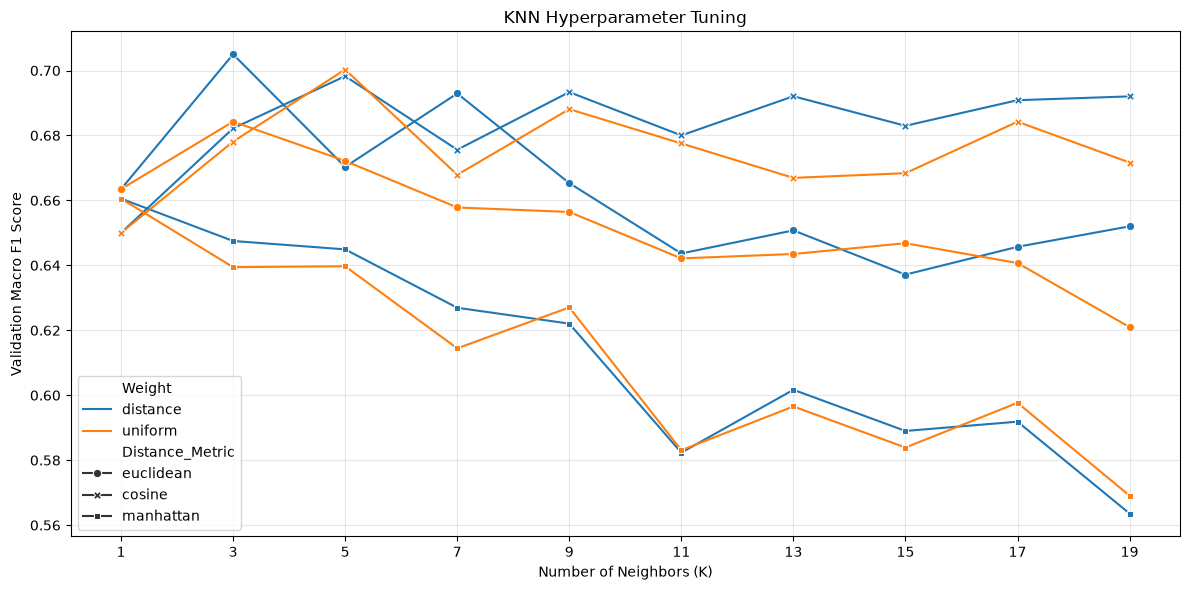

In [259]:
# Visual to show the effect of hyperparameters on F1 score

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=results_df,
    x="K",
    y="F1_Score",
    hue="Weight",
    style="Distance_Metric",
    markers=True,
    dashes=False
)

plt.title("KNN Hyperparameter Tuning")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Validation Macro F1 Score")

plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Train the KNN model

In [260]:
# combine feature and label data for training and validation sets to create a final training set
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

print("Final training set shape:", X_train_final.shape, y_train_final.shape)

Final training set shape: (847, 94) (847,)


In [261]:
final_knn = Pipeline([
    ("scaler", StandardScaler()),

    ("knn", KNeighborsClassifier(n_neighbors= best_k, weights=best_weight, metric=best_metric))
])

# train the final model on the combined training and validation data
final_knn.fit(X_train_final, y_train_final)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","[""Azara's Spinetail"",'Eurasian Nuthatch','European Robin','Mourning Dove', 'Yellowhammer']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](94,)","['mfcc_mean_1','mfcc_mean_2','mfcc_mean_3',...,'contrast_std_5', 'contrast_std_6','contrast_std_7']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,94
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Saves the scaler and classifier so you don't hve to fit them again when making predictions

In [262]:
# Save the complete pipeline
joblib.dump(
    {
        "model": final_knn,
        "feature_columns": feature_columns,
        "species": sorted(y_train.unique())
    },
    "best_knn_model.joblib"
)

print("Model saved")

Model saved


Evaluating the Model

In [263]:
# making predictions on testing data

y_pred = final_knn.predict(X_test)

In [265]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("RESULTS")


print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

RESULTS
Accuracy:  0.6933 (69.33%)
Precision: 0.7335
Recall:    0.6933
F1 Score:  0.6874
